# 04 · Redes recurrentes: memoria y gradientes en el tiempo

**Objetivo:** construir una RNN a mano y verificar que coincide con `nn.RNN`, y medir en una
tarea de memoria pura hasta qué distancia recuerdan una RNN simple, una LSTM y una GRU.

Una RNN aplica la misma celda en cada paso: $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$.
Desenrollada en el tiempo es una red profunda con pesos compartidos; el gradiente hacia el pasado
se multiplica por $W_h^\top \text{diag}(1 - h^2)$ en cada paso.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
import torch
from torch import nn

torch.manual_seed(0)

## 1. Una RNN a mano = `nn.RNN`

In [2]:
rnn = nn.RNN(input_size=3, hidden_size=5, batch_first=True)
x = torch.randn(2, 7, 3)
out_ref, h_ref = rnn(x)

Wx, Wh = rnn.weight_ih_l0, rnn.weight_hh_l0
b = rnn.bias_ih_l0 + rnn.bias_hh_l0
h = torch.zeros(2, 5)
outs = []
for t in range(x.shape[1]):
    h = torch.tanh(x[:, t] @ Wx.T + h @ Wh.T + b)
    outs.append(h)
manual = torch.stack(outs, dim=1)
print("máx. diferencia con nn.RNN:", (manual - out_ref).abs().max().item())

máx. diferencia con nn.RNN: 5.960464477539063e-08


## 2. Tarea de memoria: recordar el primer símbolo

Secuencias de longitud $T$: el primer paso trae uno de 4 símbolos (one-hot) y el resto es ruido.
La etiqueta es ese primer símbolo. Para acertar, la red debe llevar la información a través de
$T - 1$ pasos sin olvidarla. Azar = 25 %.

RNN                                {10: 1.0, 30: 0.48, 60: 0.74, 100: 0.26}
LSTM (init. por defecto)           {10: 1.0, 30: 0.27, 60: 0.26, 100: 0.24}
LSTM (sesgo de olvido = 3)         {10: 1.0, 30: 1.0, 60: 1.0, 100: 0.49}
GRU (sesgo de actualización = 3)   {10: 1.0, 30: 1.0, 60: 1.0, 100: 1.0}


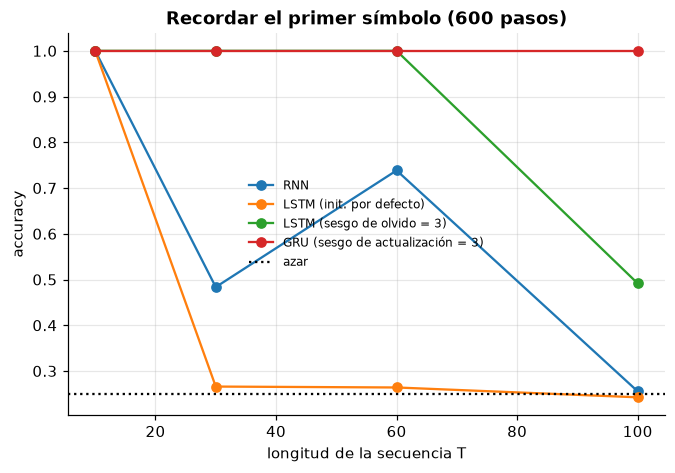

In [3]:
def memory_task(n, T, g):
    x = g.normal(0, 1, size=(n, T, 4)).astype(np.float32) * 0.5
    y = g.integers(0, 4, n)
    x[:, 0] = np.eye(4, dtype=np.float32)[y] * 3
    return torch.from_numpy(x), torch.from_numpy(y)


class SeqClassifier(nn.Module):
    def __init__(self, cell, gate_bias=None):
        super().__init__()
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell](4, 32, batch_first=True)
        self.head = nn.Linear(32, 4)
        if gate_bias is not None:  # LSTM [i, f, g, o]: olvido; GRU [r, z, n]: actualización
            H = self.rnn.hidden_size
            with torch.no_grad():
                for b in (self.rnn.bias_ih_l0, self.rnn.bias_hh_l0):
                    b[H : 2 * H].fill_(gate_bias / 2)  # PyTorch suma ambos sesgos

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1])


VARIANTS = {
    "RNN": ("RNN", None),
    "LSTM (init. por defecto)": ("LSTM", None),
    "LSTM (sesgo de olvido = 3)": ("LSTM", 3.0),
    "GRU (sesgo de actualización = 3)": ("GRU", 3.0),
}


def train_memory(cell, gate_bias, T, steps=600, seed=0):
    torch.manual_seed(seed)
    g = np.random.default_rng(seed)
    model = SeqClassifier(cell, gate_bias)
    opt = torch.optim.Adam(model.parameters(), lr=1e-2)
    for _ in range(steps):
        xb, yb = memory_task(64, T, g)
        loss = nn.functional.cross_entropy(model(xb), yb)
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # evita explosiones
        opt.step()
    xt, yt = memory_task(2000, T, np.random.default_rng(999))
    with torch.no_grad():
        return (model(xt).argmax(1) == yt).float().mean().item()


lengths = [10, 30, 60, 100]
results = {name: [train_memory(*v, T) for T in lengths] for name, v in VARIANTS.items()}
fig, ax = plt.subplots()
for name, accs in results.items():
    ax.plot(lengths, accs, "o-", label=name)
ax.axhline(0.25, color="k", ls=":", label="azar")
ax.set(
    xlabel="longitud de la secuencia T",
    ylabel="accuracy",
    title="Recordar el primer símbolo (600 pasos)",
)
ax.legend(fontsize=8)
for name, accs in results.items():
    print(f"{name:<34}", dict(zip(lengths, np.round(accs, 2).tolist(), strict=True)))

**La LSTM con la inicialización por defecto de PyTorch no supera a la RNN simple: falla desde
T = 30.** El sesgo de su compuerta de olvido empieza en 0, así que $f = \sigma(0) = 0.5$: la
celda multiplica su memoria por ~0.5 en cada paso y tras 30 pasos queda $0.5^{30} \approx 10^{-9}$
de la señal. No hay gradiente para aprender a recordar.

Iniciando ese sesgo en un valor positivo ($f \approx \sigma(3) = 0.95$ al comienzo), la LSTM y la
GRU resuelven secuencias mucho más largas que la RNN. La arquitectura con compuertas *permite*
recordar; la inicialización decide si el entrenamiento lo descubre (Jozefowicz et al., 2015,
recomiendan sesgo de olvido ≥ 1).

## 3. ¿Cuánto gradiente llega al pasado?

Para un modelo sin entrenar, norma de $\partial L / \partial x_t$ en cada paso de una secuencia
de 100: cuánta señal de aprendizaje recibe cada posición.

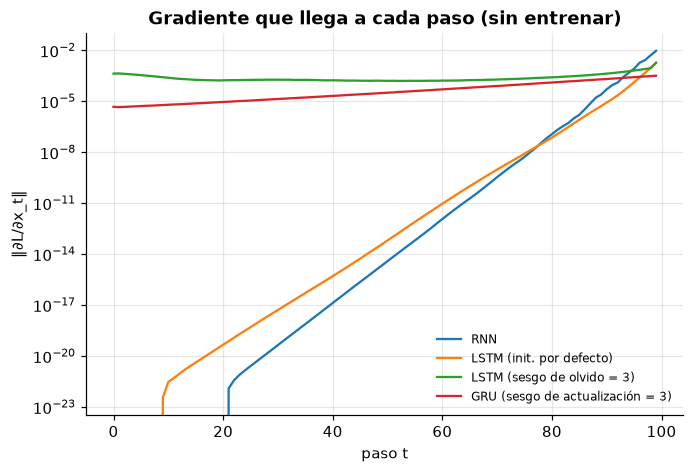

In [4]:
T = 100
xt, yt = memory_task(256, T, np.random.default_rng(5))
fig, ax = plt.subplots()
for name, (cell, gate_bias) in VARIANTS.items():
    torch.manual_seed(0)
    model = SeqClassifier(cell, gate_bias)
    xg = xt.clone().requires_grad_(True)
    nn.functional.cross_entropy(model(xg), yt).backward()
    ax.semilogy(range(T), xg.grad.norm(dim=(0, 2)).numpy(), label=name)
ax.set(xlabel="paso t", ylabel="‖∂L/∂x_t‖", title="Gradiente que llega a cada paso (sin entrenar)")
ax.legend(fontsize=8);

En la RNN y en la LSTM con inicialización por defecto, el gradiente que llega a los primeros
pasos decae **exponencialmente** con la distancia: por debajo de $10^{-20}$ antes del paso 20, menos
de lo que float32 puede representar. El modelo literalmente no recibe señal para aprender de ellos.
Con el sesgo de la compuerta en 3, la LSTM y la GRU mantienen el gradiente aproximadamente plano
a lo largo de las 100 posiciones: el camino aditivo de la celda funciona solo si las compuertas
empiezan abiertas.

## Para llevar

- Una RNN es una red profunda en el tiempo con pesos compartidos: hereda gradientes que se
  desvanecen o explotan (lo segundo se controla con *gradient clipping*).
- LSTM/GRU agregan un camino aditivo regulado por compuertas: la memoria puede persistir sin
  multiplicarse por $W_h$ en cada paso.
- Para secuencias largas hoy dominan los transformers (atención directa entre posiciones):
  se ven en PLN, semestre 2.